<a href="https://colab.research.google.com/github/Mr-Jeffrey33/classifying_rna_transfer_learning_iot/blob/main/TransferLearning_IoT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import os
import shutil

# Baixa o dataset de flores público do TensorFlow
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, extract=True)
parent_dir = os.path.dirname(data_dir)

# Caminho de origem extraído e pasta de destino
extracted_path = os.path.join(parent_dir, 'flower_photos')
destination_path = 'dataset'

# Remove a pasta 'dataset' antiga se existir e move as flores para lá
if os.path.exists(destination_path):
    shutil.rmtree(destination_path)

shutil.move(extracted_path, destination_path)
print("Dataset baixado e preparado com sucesso na pasta 'dataset'!")
# Lista as classes baixadas
print("Classes disponíveis:", sorted(os.listdir(destination_path)))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step
Dataset baixado e preparado com sucesso na pasta 'dataset'!
Classes disponíveis: ['flower_photos']


In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# Parâmetros de imagem e lote
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

# Ajustado o caminho para apontar para a subpasta correta onde as classes de flores estão
DATASET_PATH = 'dataset/flower_photos'

# 1. Carrega dados de treino (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# 2. Carrega dados de validação (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# Salva os nomes das classes antes de otimizar o dataset
class_names = train_ds.class_names

# Otimização de leitura de memória
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

print('Classes detectadas:', class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes detectadas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
import os
import shutil

# Caminho base do dataset ativo usado no treinamento
dataset_path = "dataset/flower_photos"

# Mapeamento para renomear as pastas de flores para nomes limpos em português
renomeacoes = {
    "daisy": "margarida",
    "dandelion": "dente_de_leao",
    "roses": "rosa",
    "sunflowers": "girassol",
    "tulips": "tulipa"
}

# Executa a renomeação se as pastas originais existirem
if os.path.exists(dataset_path):
    for nome_antigo, nome_novo in renomeacoes.items():
        caminho_antigo = os.path.join(dataset_path, nome_antigo)
        caminho_novo = os.path.join(dataset_path, nome_novo)
        if os.path.exists(caminho_antigo):
            os.rename(caminho_antigo, caminho_novo)
            print(f"🔄 Renomeado: '{nome_antigo}' -> '{nome_novo}'")

# Compacta a pasta de flores ativa em um arquivo zip
shutil.make_archive("dataset_flores", "zip", dataset_path)

print("📁 Dataset de flores organizado e compactado em 'dataset_flores.zip'!")

🔄 Renomeado: 'daisy' -> 'margarida'
🔄 Renomeado: 'dandelion' -> 'dente_de_leao'
🔄 Renomeado: 'roses' -> 'rosa'
🔄 Renomeado: 'sunflowers' -> 'girassol'
🔄 Renomeado: 'tulips' -> 'tulipa'
📁 Dataset de flores organizado e compactado em 'dataset_flores.zip'!


Agora testar o treinamento realizado

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Carrega a base pré-treinada MobileNetV2 (sem a camada final de classificação)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3), include_top=False, weights='imagenet'
)

# 2. CONGELA a base: preserva o conhecimento visual prévio (passado)
base_model.trainable = False

# 3. Monta a nova rede: Pré-processamento + Base Congelada + Mais Neurônios
modelo_transfer = models.Sequential([
    # Agora envelopamos a função de pré-processamento em uma camada Lambda
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input, input_shape=(128, 128, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    # Aumentamos a capacidade: 128 neurônios com Dropout para evitar sobreajuste
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    # Camada final de saída configurada para 5 classes (com ativação softmax)
    layers.Dense(5, activation='softmax'),
])

# 4. Compilação usando sparse_categorical_crossentropy para classificação multiclasse
modelo_transfer.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

print('Treinando o Modelo Otimizado com Transfer Learning...')
hist_transfer = modelo_transfer.fit(
    train_ds, validation_data=val_ds, epochs=10
)

Treinando o Modelo Otimizado com Transfer Learning...
Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 67s 305ms/step - accuracy: 0.7933 - loss: 0.5658 - val_accuracy: 0.8747 - val_loss: 0.3545
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 70s 276ms/step - accuracy: 0.9108 - loss: 0.2549 - val_accuracy: 0.8774 - val_loss: 0.3218
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 82s 276ms/step - accuracy: 0.9441 - loss: 0.1632 - val_accuracy: 0.9005 - val_loss: 0.2915
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 49s 268ms/step - accuracy: 0.9704 - loss: 0.0909 - val_accuracy: 0.8828 - val_loss: 0.3334
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 84s 277ms/step - accuracy: 0.9881 - loss: 0.0508 - val_accuracy: 0.8719 - val_loss: 0.4015
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 82s 276ms/step - accuracy: 0.9894 - loss: 0.0422 - val_accuracy: 0.8883 - val_loss: 0.3725
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 49s 265ms/step - accuracy: 0.9935 - loss: 0.0279 - val_accuracy: 0.8992 - val_loss: 0.3657
Epoch 8/10
184/184 ━━━━━━━━━━

Agora será feita a otimização do transfer learning para comparativo entre a primeira versão e a otimizada em rede, neurônios, para via de estudo

In [ ]:
# Salva o histórico da 1ª leva
hist_leva1 = hist_transfer

In [ ]:
#Agora é a segunda leva
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Pipeline de Data Augmentation (Variação de dados em tempo real)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

# 2. Base Pré-treinada MobileNetV2
base_model_otimizado = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3), include_top=False, weights="imagenet"
)
base_model_otimizado.trainable = False

# 3. Nova Arquitetura Otimizada (Mais neurônios + Regularização)
modelo_otimizado = models.Sequential([
    # Envelopamos a função de pré-processamento em uma camada Lambda
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input, input_shape=(128, 128, 3)),
    data_augmentation,
    base_model_otimizado,
    layers.GlobalAveragePooling2D(),
    # Aumentando neurônios: Camada 1 com 256 neurônios
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),  # Regularização para evitar memorização
    # Camada 2 com 128 neurônios
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    # Saída ajustada para as 5 classes de flores existentes
    layers.Dense(5, activation="softmax"),
])

# 4. Compilação ajustada para classificação multiclasse
modelo_otimizado.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Treinando o Modelo Otimizado (2ª Leva com 256 neurônios + Augmentation)...")
hist_leva2 = modelo_otimizado.fit(train_ds, validation_data=val_ds, epochs=10)

Treinando o Modelo Otimizado (2ª Leva com 256 neurônios + Augmentation)...
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/lambda_layer.py:65: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


184/184 ━━━━━━━━━━━━━━━━━━━━ 129s 351ms/step - accuracy: 0.6652 - loss: 0.8685 - val_accuracy: 0.8243 - val_loss: 0.4570
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 81s 346ms/step - accuracy: 0.8127 - loss: 0.5184 - val_accuracy: 0.8324 - val_loss: 0.4282
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 62s 337ms/step - accuracy: 0.8321 - loss: 0.4685 - val_accuracy: 0.8460 - val_loss: 0.3757
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 63s 345ms/step - accuracy: 0.8566 - loss: 0.4042 - val_accuracy: 0.8474 - val_loss: 0.3855
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 82s 345ms/step - accuracy: 0.8604 - loss: 0.3729 - val_accuracy: 0.8515 - val_loss: 0.3509
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 62s 336ms/step - accuracy: 0.8750 - loss: 0.3500 - val_accuracy: 0.8597 - val_loss: 0.3478
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 64s 346ms/step - accuracy: 0.8774 - loss: 0.3490 - val_accuracy: 0.8597 - val_loss: 0.3635
Epoch 8/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 61s 335ms/step - accuracy: 0.8856 - loss: 0.3096 - va

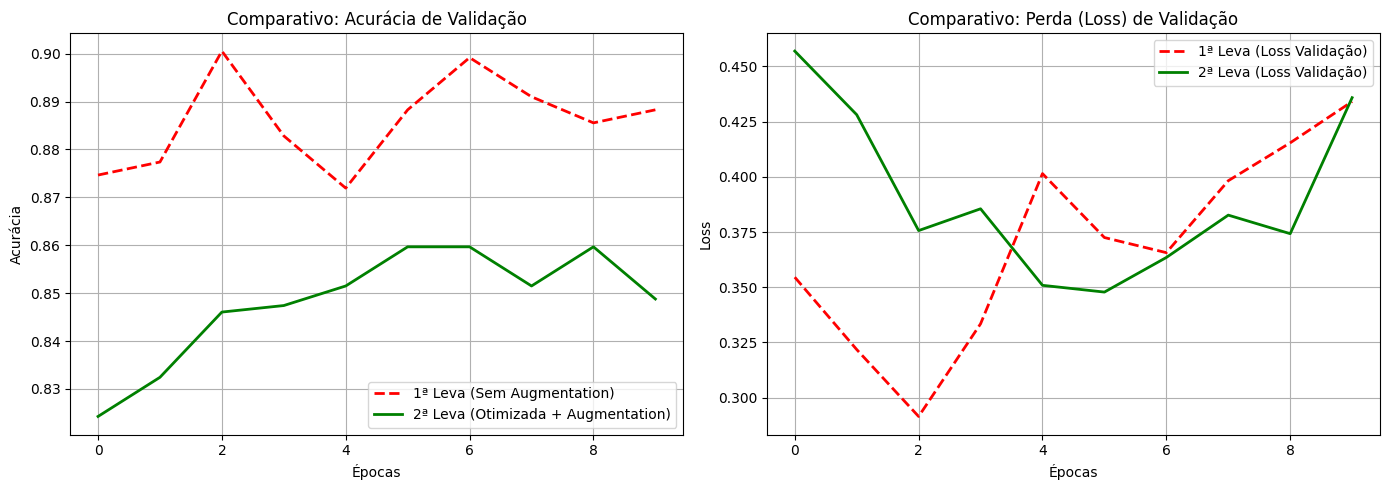

In [ ]:
#Gráfico de comparação entre os testes:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Gráfico 1: Acurácia de Validação
plt.subplot(1, 2, 1)
plt.plot(
    hist_leva1.history['val_accuracy'],
    'r--',
    label='1ª Leva (Sem Augmentation)',
    linewidth=2,
)
plt.plot(
    hist_leva2.history['val_accuracy'],
    'g-',
    label='2ª Leva (Otimizada + Augmentation)',
    linewidth=2,
)
plt.title('Comparativo: Acurácia de Validação')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# Gráfico 2: Loss de Validação
plt.subplot(1, 2, 2)
plt.plot(
    hist_leva1.history['val_loss'],
    'r--',
    label='1ª Leva (Loss Validação)',
    linewidth=2,
)
plt.plot(
    hist_leva2.history['val_loss'],
    'g-',
    label='2ª Leva (Loss Validação)',
    linewidth=2,
)
plt.title('Comparativo: Perda (Loss) de Validação')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()